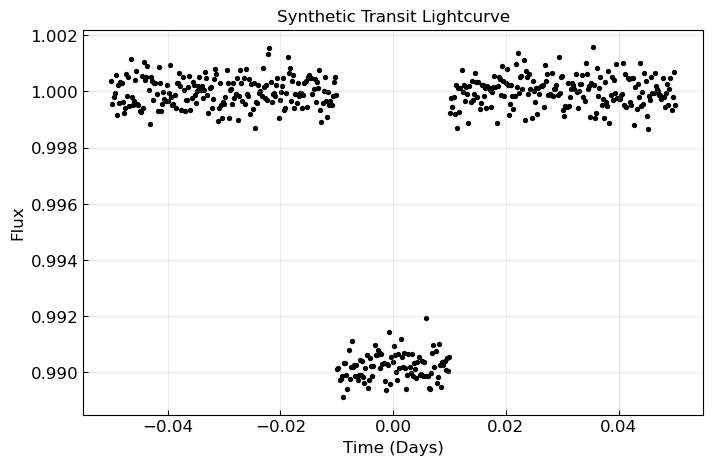

Best center: -3.469446951953614e-18
Best width: 0.02
Best depth: 0.00978652052253744
Uncertainties: inf inf inf


C:\Users\FiveM\Desktop\ast4762\hw9_lebronjames\hw8_lebronjames_practicumfile.py:105: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(roddyrich, time, flux, p0=[guesscenter, guesswidth, guessdepth])


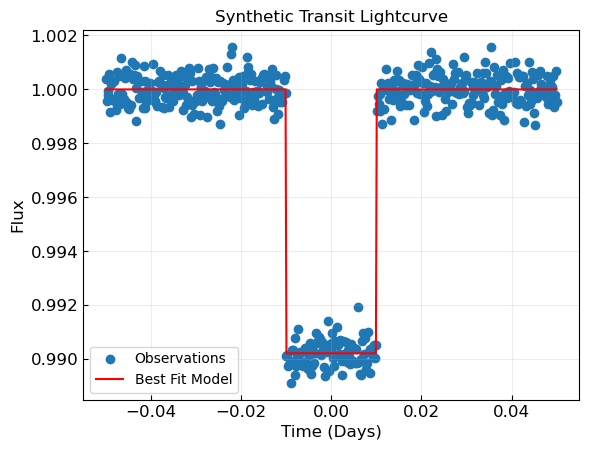

Planet radius: 0.11277660249843341
Planetary Radius Uncertainty:  0.011566051642958465
Normalization factors: [10864.  11057.  10536.  10558.5 11046.  10623.   9916.5  9916.5  9859.5]
Shape of Combined Image: (1024, 1024)
-97.3820904553013
(1024, 1024)


In [1]:
#Shiloh
# AST 4762C - Astronomical Data Analysis
# Homework 9 - Photometry Setup


import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt

from hw8_lebronjames_practicumfile import normmedcomb, skycormednorm

In [2]:
data= fits.getdata("darkdataforprac5.fits")

region = ((225,225), (-225, -225))
sky, normfactor = normmedcomb(data, region)

corrected = np.array([
    skycormednorm(data[i], sky, region)
    for i in range(3)
])

print(corrected.shape)

(3, 1024, 1024)


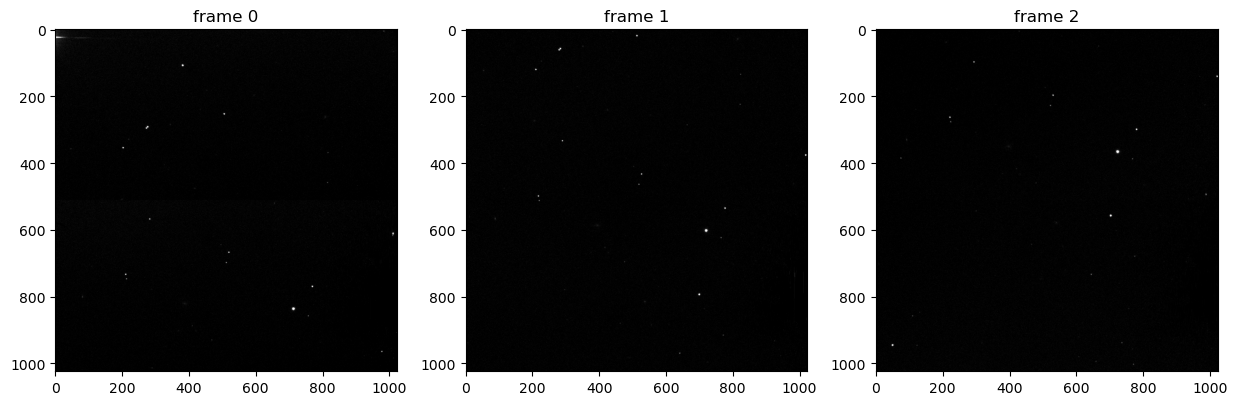

In [3]:
fig, axes = plt.subplots(1,3, figsize=(15,5))

for i in range(3):
    axes[i].imshow(corrected[i], cmap='gray', vmin=0, vmax=3000)
    axes[i].set_title(f"frame {i}")

plt.show()

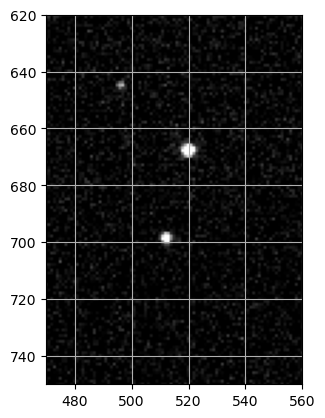

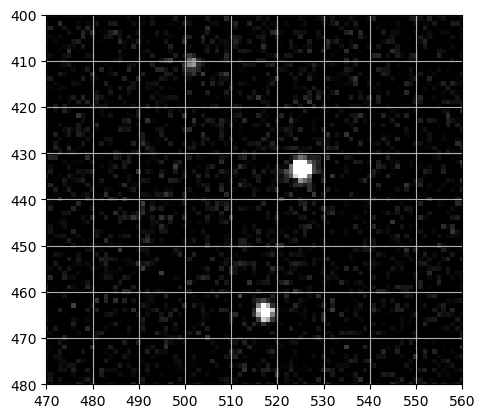

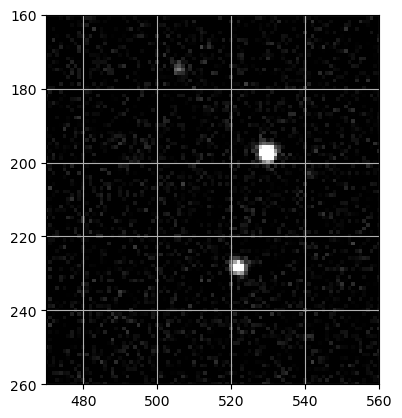

In [4]:
plt.imshow(corrected[0], cmap='gray', vmin=0, vmax=1000)
plt.xlim(470, 560)
plt.ylim(750, 620)
plt.grid()
plt.show()

plt.imshow(corrected[1], cmap='gray', vmin=0, vmax=1000)
plt.xlim(470, 560)
plt.ylim(480, 400)
plt.grid()
plt.show()

plt.imshow(corrected[2], cmap='gray', vmin=0, vmax=1000)
plt.xlim(470, 560)
plt.ylim(260, 160)
plt.grid()
plt.show()

In [5]:
#Stellar photometry:
#Params: yguess, xguess, width, cy, cx, star, sky

photometry = np.array([
 [ [698, 512, np.nan, np.nan, np.nan, np.nan, np.nan],   
   [464, 518, np.nan, np.nan, np.nan, np.nan, np.nan], 
   [228, 522, np.nan, np.nan, np.nan, np.nan, np.nan] ],
 [ [668, 520, np.nan, np.nan, np.nan, np.nan, np.nan],
   [np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan],
   [np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan] ],
 [ [568, 283, np.nan, np.nan, np.nan, np.nan, np.nan],
   [np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan],
   [np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan] ]
], dtype=float)

In [6]:
y0, x0 = photometry[0,0,0], photometry[0,0,1]  
y1, x1 = photometry[0,1,0], photometry[0,1,1]  
y2, x2 = photometry[0,2,0], photometry[0,2,1]  


dy1 = y1 - y0
dx1 = x1 - x0
dy2 = y2 - y0
dx2 = x2 - x0

In [7]:
howmanystars = photometry.shape[0]

for s in range(1, howmanystars):
    photometry[s,1,0] = photometry[s,0,0] + dy1
    photometry[s,1,1] = photometry[s,0,1] + dx1
    photometry[s,2,0] = photometry[s,0,0] + dy2
    photometry[s,2,1] = photometry[s,0,1] + dx2

In [8]:
from scipy.optimize import curve_fit

def gaussian2d(coords, amplitude, cy, cx, sigy, sigx):
    y, x = coords
    return amplitude * np.exp(
        -0.5 * (((y-cy)/sigy)**2 + ((x-cx)/sigx)**2)
    )

nstars, nframes, nparams = photometry.shape

for star in range(nstars):
    for frame in range(nframes):

        yguess = int(round(photometry[star, frame, 0]))
        xguess = int(round(photometry[star, frame, 1]))

        radius = 12
        ylo = max(0, yguess-radius)
        yhi = min(corrected.shape[1], yguess+radius+1)
        xlo = max(0, xguess-radius)
        xhi = min(corrected.shape[2], xguess+radius+1)

        subimage = corrected[frame, ylo:yhi, xlo:xhi].copy()
        subimage -= np.nanmedian(subimage)

        yy, xx = np.indices(subimage.shape)
        valid = np.isfinite(subimage)

        p0 = [
            np.nanmax(subimage),
            yguess-ylo,
            xguess-xlo,
            2.5,
            2.5
        ]

        lower = [0, 0, 0, 0.5, 0.5]
        upper = [
            np.inf,
            subimage.shape[0],
            subimage.shape[1],
            10,
            10
        ]

        popt, pcov = curve_fit(
            gaussian2d,
            (yy[valid], xx[valid]),
            subimage[valid],
            p0=p0,
            bounds=(lower, upper)
        )

        amplitude, cy, cx, sigy, sigx = popt

        width_avg = (sigy + sigx) / 2

        cy_global = cy + ylo
        cx_global = cx + xlo

    
        photometry[star, frame, 2] = width_avg
        photometry[star, frame, 3] = cy_global
        photometry[star, frame, 4] = cx_global

print(photometry)
np.save("hw9_photometry.npy", photometry)
"""
Final photometry table:

[[[698.         512.           1.00574603 698.57622874 512.37671783
            nan          nan]
  [464.         518.           0.94111324 464.34201052 517.38298625
            nan          nan]
  [228.         522.           1.1260318  228.39021354 521.92886915
            nan          nan]]

 [[668.         520.           1.0587809  667.87250717 520.24964647
            nan          nan]
  [434.         526.           1.00064029 433.5720728  525.34078644
            nan          nan]
  [198.         530.           1.17258263 197.63371258 529.75147069
            nan          nan]]

 [[568.         283.           1.04958606 568.26505819 283.30170791
            nan          nan]
  [334.         289.           0.99776984 333.99275949 288.33910402
            nan          nan]
  [ 98.         293.           1.09655216  98.06640046 292.88961575
            nan          nan]]]

The fitted positions are consistent with the
initial coordinate estimates.
"""

[[[698.         512.           1.00574603 698.57622874 512.37671783
            nan          nan]
  [464.         518.           0.94111324 464.34201052 517.38298625
            nan          nan]
  [228.         522.           1.1260318  228.39021354 521.92886915
            nan          nan]]

 [[668.         520.           1.0587809  667.87250717 520.24964647
            nan          nan]
  [434.         526.           1.00064029 433.5720728  525.34078644
            nan          nan]
  [198.         530.           1.17258263 197.63371258 529.75147069
            nan          nan]]

 [[568.         283.           1.04958606 568.26505819 283.30170791
            nan          nan]
  [334.         289.           0.99776984 333.99275949 288.33910402
            nan          nan]
  [ 98.         293.           1.09655216  98.06640046 292.88961575
            nan          nan]]]


'\nFinal photometry table:\n\n[[[698.         512.           1.00574603 698.57622874 512.37671783\n            nan          nan]\n  [464.         518.           0.94111324 464.34201052 517.38298625\n            nan          nan]\n  [228.         522.           1.1260318  228.39021354 521.92886915\n            nan          nan]]\n\n [[668.         520.           1.0587809  667.87250717 520.24964647\n            nan          nan]\n  [434.         526.           1.00064029 433.5720728  525.34078644\n            nan          nan]\n  [198.         530.           1.17258263 197.63371258 529.75147069\n            nan          nan]]\n\n [[568.         283.           1.04958606 568.26505819 283.30170791\n            nan          nan]\n  [334.         289.           0.99776984 333.99275949 288.33910402\n            nan          nan]\n  [ 98.         293.           1.09655216  98.06640046 292.88961575\n            nan          nan]]]\n\nThe fitted positions are consistent with the\ninitial coordi

In [9]:
wmean = np.nanmean(photometry[:,:,2])
rap   = 2.5 * wmean        
rin   = 4.0 * wmean        
rout  = 6.0 * wmean        
subsz  = 7.5 * wmean  

print("Average width:", wmean)
print("Aperture radius:", rap)
print("Inner sky radius:", rin)
print("Outer sky radius:", rout)
print("Subimage half-width:", subsz)

#Aperture radius is 2.5*sigma, capturing 95% of the star's flux. The sky annulus begins at 4*sigma to reduce contamination from the star and ends at 6*sigma to provide a measurement for the background
#Subimage half-width is 7.5*sigma, so the entire annulus fits within the frame

Average width: 1.0498669947696773
Aperture radius: 2.624667486924193
Inner sky radius: 4.199467979078709
Outer sky radius: 6.299201968618064
Subimage half-width: 7.874002460772579
